In [1]:
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
import yaml
from sklearn.metrics import roc_auc_score


/Users/jonatanhalperin/NTNU_master/fall_2026_courses/MML_in_practice/sintef_project/venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# load data
water_value = pd.read_csv("data/kernel/Synthetic_water_value_2015_2024.csv",
    parse_dates=["date"],
    index_col="date"
)

volume = pd.read_csv("data/kernel/Historical_volume_2015_2024.csv",
    parse_dates=["date"],
    index_col="date"
)

day_ahead_price = pd.read_csv("data/kernel/Historical_day_ahead_price_2015_2025.csv",
    parse_dates=["date"],
    index_col="date"
)

# rename price column and resample to hourly for the 15 minute interval period
day_ahead_price = day_ahead_price.rename(columns={"Day-ahead price (EUR/MWh)": "price"})
day_ahead_price = day_ahead_price.resample("h").mean()

inflow = pd.read_csv("data/kernel/Historical_inflow_1958_2025.csv",
    parse_dates=["date"],
    index_col="date"
)

# Unit commitment decisions have no date column, so we use starttime instead
unit_commitment_decisions = pd.read_csv("data/kernel/Unit_commitment_decisions.csv",
    parse_dates=["starttime"],
    index_col="starttime"
)

# drop the timezone for consistency
water_value.index = water_value.index.tz_convert(None)
volume.index = volume.index.tz_convert(None)
day_ahead_price.index = day_ahead_price.index.tz_convert(None)
inflow.index = inflow.index.tz_convert(None)

# reservoir fill level as a share of max volume (max_vol from the topology file)
with open("data/extended/Tokke_Vinje_topology.yaml") as f:
    topology = yaml.safe_load(f)

max_vol = pd.Series({name: r["max_vol"] for name, r in topology["model"]["reservoir"].items()})
fill = volume / max_vol

# test cases (2023–2024) to predict for Kaggle
test_cases = pd.read_csv("prediction_mapping.csv", parse_dates=["starttime"])

# Max flow (m³/s) each unit can use at full load = the largest flow value in its turbine efficiency curves
unit_max_flow = {gen: max(max(curve["x"]) for curve in g["turb_eff_curves"])
                 for gen, g in topology["model"]["generator"].items()}

plant_max_flow = {}
for gen, q in unit_max_flow.items():
    plant = gen.rsplit("_G", 1)[0]
    plant_max_flow[plant] = plant_max_flow.get(plant, 0) + q   # plant total = sum of its units

plant_max_flow

{'Hogga': 168.6,
 'Tokke': 128,
 'Lio': 14,
 'Byrte': 8,
 'Vinje': 165,
 'Haukeli': 2.1,
 'Songa': 52,
 'Kjela': 40,
 'Vesle Kjela': 20}

In [3]:
# Constraints (extended data): hourly minimum flow per river (m³/s) and minimum volume per reservoir (Mm³)
min_flow = pd.read_csv("data/extended/Constraint_min_flow.csv", parse_dates=["date"], index_col="date")
min_volume = pd.read_csv("data/extended/Constraint_min_volume.csv", parse_dates=["date"], index_col="date")
min_flow.index = min_flow.index.tz_convert(None)
min_volume.index = min_volume.index.tz_convert(None)
print("min flow:", min_flow.columns.tolist())
print("min volume:", min_volume.columns.tolist())

min flow: ['b_Kjelavatn', 'b_Hyljelihyl', 'b_Vinjevatn', 'b_Byrtevatn', 'b_Bandak', 'r_Vest_Vassdraget']
min volume: ['Totak', 'Byrtevatn', 'Staavatn']


In [4]:
#Find the units in column names
label_cols = [c for c in unit_commitment_decisions.columns if c.startswith("result_committed")]

units = []
for c in label_cols:
    unit = c.replace("result_committed_", "").rsplit("_t", 1)[0] # making the names: "Hogga_G1_t5" -> "Hogga_G1"
    if unit not in units:
        units.append(unit)

print(len(units), units)

# The columns come in order: all 168 hours for unit 1, then all 168 for unit 2, up to 14
Y = unit_commitment_decisions[label_cols].to_numpy().reshape(len(unit_commitment_decisions), len(units), 168)
print(Y.shape)

assert (Y[0, 0, :] == unit_commitment_decisions.filter(like="Hogga_G1_t").iloc[0].to_numpy()).all()
assert (Y[5, 13, :] == unit_commitment_decisions.filter(like="Vesle Kjela_G1_t").iloc[5].to_numpy()).all()
print("Reshape OK, labels only 0/1:", set(pd.unique(Y.ravel())))

14 ['Hogga_G1', 'Tokke_G1', 'Tokke_G2', 'Tokke_G3', 'Tokke_G4', 'Lio_G1', 'Byrte_G1', 'Vinje_G1', 'Vinje_G2', 'Vinje_G3', 'Haukeli_G1', 'Songa_G1', 'Kjela_G1', 'Vesle Kjela_G1']
(2922, 14, 168)
Reshape OK, labels only 0/1: {np.int64(0), np.int64(1)}


In [5]:
# Find which reservoir(s) each plant draws water from, using the topology file
plant_sources = {}
for conn in topology["connections"]:
    if conn["to_type"] == "plant" and conn["from_type"] in ("reservoir", "tunnel"):
        plant_sources.setdefault(conn["to"], []).append(conn["from"])

# Some plants get water through a tunnel: replace the tunnel with the reservoir it starts at
tunnel_sources = {conn["to"]: conn["from"] for conn in topology["connections"]
                  if conn["to_type"] == "tunnel" and conn["from_type"] == "reservoir"}
plant_reservoir = {plant: [tunnel_sources.get(s, s) for s in sources]
                   for plant, sources in plant_sources.items()}

for plant, reservoirs in plant_reservoir.items():
    print(f"{plant:12s} <- {reservoirs}")

# Which reservoir each plant releases its water into (downstream)
plant_downstream = {}
for conn in topology["connections"]:
    if conn["from_type"] == "plant" and conn["to_type"] == "reservoir":
        plant_downstream[conn["from"]] = [conn["to"]]
plant_downstream["Lio"] = ["Bandak"]   # Lio -> river r_Vest_Vassdraget -> Bandak
plant_downstream["Hogga"] = []         # Hogga is at the bottom: the water leaves the system

for plant in plant_reservoir:
    print(f"{plant:12s} {plant_reservoir[plant]} -> {plant_downstream[plant]}")

# Which plants release water into the reservoir(s) this plant draws from
plant_upstream = {plant: [other for other, down in plant_downstream.items()
                          if set(down) & set(plant_reservoir[plant])]
                  for plant in plant_reservoir}
plant_upstream["Vinje"] = ["Songa"]   # Songa -> Totak -> tunnel -> Vaamarvatn (not a direct connection)
plant_upstream

Hogga        <- ['Bandak']
Tokke        <- ['Vinjevatn']
Lio          <- ['Byrtevatn']
Byrte        <- ['Botnedalsvatn']
Vinje        <- ['Vaamarvatn']
Haukeli      <- ['Vatjern']
Songa        <- ['Songavatn', 'Bitdalsvatn']
Kjela        <- ['Foersvatn']
Vesle Kjela  <- ['Kjelavatn']
Hogga        ['Bandak'] -> []
Tokke        ['Vinjevatn'] -> ['Bandak']
Lio          ['Byrtevatn'] -> ['Bandak']
Byrte        ['Botnedalsvatn'] -> ['Byrtevatn']
Vinje        ['Vaamarvatn'] -> ['Vinjevatn']
Haukeli      ['Vatjern'] -> ['Vinjevatn']
Songa        ['Songavatn', 'Bitdalsvatn'] -> ['Totak']
Kjela        ['Foersvatn'] -> ['Hyljelihyl']
Vesle Kjela  ['Kjelavatn'] -> ['Foersvatn']


{'Hogga': ['Tokke', 'Lio'],
 'Tokke': ['Vinje', 'Haukeli'],
 'Lio': ['Byrte'],
 'Byrte': [],
 'Vinje': ['Songa'],
 'Haukeli': [],
 'Songa': [],
 'Kjela': ['Vesle Kjela'],
 'Vesle Kjela': []}

In [6]:
# "Normal" inflow for each day of the year, from 1958–2014
inflow_daily = inflow.resample("D").mean()
inflow_normal = inflow_daily.loc[:"2014"].groupby(inflow_daily.loc[:"2014"].index.dayofyear).mean()

def hourly_matrix(series, starts):
    """168 hourly values from each start date -> shape (n_cases, 168)."""
    return np.array([series.loc[s : s + pd.Timedelta(hours=167)].to_numpy() for s in starts])

def rolling_within_case(M, window):
    """Centred rolling mean along the hours of each case."""
    return pd.DataFrame(M).T.rolling(window, center=True, min_periods=1).mean().T.to_numpy()

def daily_value(df, dates, columns):
    """Mean of the given reservoir columns on the given dates (0 if there are no reservoirs)."""
    if len(columns) == 0:
        return np.zeros(len(dates))
    return df.loc[dates, columns].mean(axis=1).to_numpy()
    

In [7]:
def build_features(starts):
    """One row per (case, unit, hour). Works for both train and test start dates."""
    starts = pd.DatetimeIndex(starts)
    ends = starts + pd.Timedelta(days=7)
    n_cases, n_hours = len(starts), 168
    rep = lambda v: np.repeat(v, n_hours)            # one value per case -> all 168 hours
    doy = np.minimum(starts.dayofyear, 365)

    # ---------- features that are the same for all units ----------
    P = hourly_matrix(day_ahead_price["price"], starts)
    desc_rank = n_hours - P.argsort(axis=1).argsort(axis=1)   # 1 = most expensive hour of the week, 168 = cheapest
    week_mean = P.mean(axis=1, keepdims=True)
    week_std = P.std(axis=1, keepdims=True) + 1e-6
    total_inflow = hourly_matrix(inflow.sum(axis=1), starts)
    total_normal = inflow_normal.sum(axis=1).loc[doy].to_numpy()
    P_after = hourly_matrix(day_ahead_price["price"], starts + pd.Timedelta(hours=168))[:, :48]   # 48 h after the week
    after24, after48 = P_after[:, :24].mean(axis=1), P_after[:, 24:].mean(axis=1)
    vest_min = hourly_matrix(min_flow["r_Vest_Vassdraget"], starts)          # required minimum flow (m³/s)
    vest_deficit = np.clip(vest_min - hourly_matrix(inflow["r_Vest_Vassdraget"], starts), 0, None)   # not covered by natural inflow

    shared = {
        "hour": np.tile(np.arange(n_hours), n_cases),
        "hour_of_day": np.tile(np.arange(n_hours) % 24, n_cases),
        "month": rep(starts.month.to_numpy()),
        "price": P.ravel(),
        "price_rank": (P.argsort(axis=1).argsort(axis=1) / (n_hours - 1)).ravel(),
        "price_z": ((P - week_mean) / week_std).ravel(),
        "price_week_mean": rep(week_mean[:, 0]),
        "price_roll6": rolling_within_case(P, 7).ravel(),
        "price_roll24": rolling_within_case(P, 25).ravel(),
        "inflow_total_week": rep(total_inflow.mean(axis=1)),
        "inflow_total_anom": rep(total_inflow.mean(axis=1) / total_normal),
        # --- group A: exact date + system-wide constraints ---
        "doy": rep(doy),
        "con_totak_minvol": (hourly_matrix(min_volume["Totak"], starts) / max_vol["Totak"]).ravel(),
        "con_staavatn_minvol": (hourly_matrix(min_volume["Staavatn"], starts) / max_vol["Staavatn"]).ravel(),
        "con_vest_minflow": vest_min.ravel(),
        # --- group D: minimum flow in Vest-Vassdraget not met by natural inflow (Lio must release water) ---
        "vest_flow_deficit": vest_deficit.ravel(),
        "vest_deficit_share": rep((vest_deficit > 0).mean(axis=1)),
    }

    # price minus end water value for every plant (used for the cascade features)
    diff_end_by_plant = {pl: P - daily_value(water_value, ends, plant_reservoir[pl])[:, None]
                         for pl in plant_reservoir}

    # ---------- features that depend on the unit's reservoirs ----------
    blocks = []
    for unit in units:
        plant = unit.rsplit("_G", 1)[0]
        up = plant_reservoir[plant]          # where the water comes from
        down = plant_downstream[plant]       # where the water goes

        wv_start = daily_value(water_value, starts, up)
        wv_end = daily_value(water_value, ends, up)                         # THE key quantity
        net_wv_end = wv_end - daily_value(water_value, ends, down)          # value lost by moving water down
        diff_end = P - wv_end[:, None]                                      # price minus end water value
        diff_net = P - net_wv_end[:, None]
        res_inflow = hourly_matrix(inflow[up].sum(axis=1), starts)
        res_normal = inflow_normal[up].sum(axis=1).loc[doy].to_numpy()

        # ---------- water budget ----------
        vol_start = volume.loc[starts, up].sum(axis=1).to_numpy()             # Mm³ in the reservoir(s) at start
        inflow_week = res_inflow.sum(axis=1) * 3600 / 1e6                     # Mm³ flowing in during the week
        free_space = max_vol[up].sum() - vol_start                            # Mm³ before the reservoir is full
        plant_per_hour = plant_max_flow[plant] * 3600 / 1e6                   # Mm³ the plant uses per hour at full load
        unit_per_hour = unit_max_flow[unit] * 3600 / 1e6

        hours_available = np.clip((vol_start + inflow_week) / plant_per_hour, 0, 168)
        hours_forced = np.clip((inflow_week - free_space) / plant_per_hour, 0, 168)
        unit_hours_available = np.clip((vol_start + inflow_week) / unit_per_hour, 0, 168)

        ups = plant_upstream[plant]
        if ups:
            up_diff = np.mean([diff_end_by_plant[q] for q in ups], axis=0)
            up_share = np.mean([(diff_end_by_plant[q] > 0).mean(axis=1) for q in ups], axis=0)
        else:
            up_diff = np.zeros_like(P)
            up_share = np.zeros(n_cases)

        # ---------- group A: constraints on the unit's own reservoir(s) ----------
        flow_cols = [f"b_{r}" for r in up if f"b_{r}" in min_flow.columns]   # minimum release from the reservoir
        vol_cols = [r for r in up if r in min_volume.columns]                # minimum volume of the reservoir
        minflow_out = hourly_matrix(min_flow[flow_cols].sum(axis=1), starts) if flow_cols else np.zeros_like(P)
        minvol_up = hourly_matrix(min_volume[vol_cols].sum(axis=1), starts) if vol_cols else np.zeros_like(P)
        minvol_headroom = np.clip((vol_start[:, None] - minvol_up) / plant_per_hour, -168, 1000)   # full-load hours above the minimum

        # ---------- group B: the water-value path through the week ----------
        W = np.stack([daily_value(water_value, starts + pd.Timedelta(days=d), up) for d in range(8)], axis=1)  # (cases, 8 days)
        wv_day = W[:, np.arange(n_hours) // 24]                                # water value of the hour's own day

        blocks.append(pd.DataFrame({
            "case": rep(np.arange(n_cases)),
            "unit": unit,
            **shared,
            "wv_start": rep(wv_start),
            "wv_end": rep(wv_end),
            "net_wv_end": rep(net_wv_end),
            "price_minus_wv_end": diff_end.ravel(),
            "ratio_price_wv_end": (P / (np.abs(wv_end[:, None]) + 1)).ravel(),
            "share_above_wv_end": rep((diff_end > 0).mean(axis=1)),
            "roll6_minus_wv_end": rolling_within_case(diff_end, 7).ravel(),
            "roll24_minus_wv_end": rolling_within_case(diff_end, 25).ravel(),
            "above_wv_end_run": rolling_within_case((diff_end > 0).astype(float), 13).ravel(),
            "price_minus_net_end": diff_net.ravel(),
            "share_above_net_end": rep((diff_net > 0).mean(axis=1)),
            "fill": rep(daily_value(fill, starts, up)),
            "fill_down": rep(daily_value(fill, starts, down)),
            "inflow_res": res_inflow.ravel(),
            "inflow_res_week": rep(res_inflow.mean(axis=1)),
            "inflow_res_anom": rep(res_inflow.mean(axis=1) / (res_normal + 1e-3)),
            "upstream_roll6_minus_wv_end": rolling_within_case(up_diff, 7).ravel(),
            "upstream_share_above": rep(up_share),
            "hours_available": rep(hours_available),
            "hours_forced": rep(hours_forced),
            "unit_hours_available": rep(unit_hours_available),
            "rank_minus_available": (desc_rank - hours_available[:, None]).ravel(),
            "rank_minus_forced": (desc_rank - hours_forced[:, None]).ravel(),
            # --- group A ---
            "minflow_out": minflow_out.ravel(),
            "minvol_up": (minvol_up / max_vol[up].sum()).ravel(),
            "minvol_headroom": minvol_headroom.ravel(),
            # --- group B ---
            "price_minus_wv_day": (P - wv_day).ravel(),
            "wv_day_rel": ((wv_day - wv_end[:, None]) / (np.abs(wv_end[:, None]) + 1)).ravel(),
            "wv_path_slope": rep((W[:, 7] - W[:, 0]) / (np.abs(W[:, 7]) + 1)),
            # --- group C: prices just after the week ---
            "after24_minus_wv_end": rep(after24 - wv_end),
            "after48_minus_wv_end": rep(after48 - wv_end),
            "after24_rel_week": rep(after24 / (np.abs(week_mean[:, 0]) + 1)),
        }))

    X = pd.concat(blocks, ignore_index=True)
    X["unit"] = pd.Categorical(X["unit"], categories=units)
    numeric = X.columns.difference(["case", "unit"])
    X[numeric] = X[numeric].astype("float32")         # saves memory
    return X

In [8]:
X = build_features(unit_commitment_decisions.index)
y = Y.transpose(1, 0, 2).ravel()      # same order as X: unit, then case, then hour

i, unit, h = 100, "Songa_G1", 37
row = X[(X["unit"] == unit) & (X["case"] == i) & (X["hour"] == h)].index[0]
assert y[row] == Y[i, units.index(unit), h]
X.shape                               # (6872544, 51)

(6872544, 51)

In [9]:
absolute_levels = ["price", "price_week_mean", "price_roll6", "price_roll24", "wv_start", "wv_end"]
feat_A = ["doy", "con_totak_minvol", "con_staavatn_minvol", "con_vest_minflow",
          "minflow_out", "minvol_up", "minvol_headroom"]                        # constraints + exact date
feat_B = ["price_minus_wv_day", "wv_day_rel", "wv_path_slope"]                   # water-value path in the week
feat_C = ["after24_minus_wv_end", "after48_minus_wv_end", "after24_rel_week"]    # prices just after the week
feat_D = ["vest_flow_deficit", "vest_deficit_share"]                             # Lio's minimum-flow deficit
v6_features = [c for c in X.columns if c not in ["case"] + absolute_levels + feat_A + feat_B + feat_C + feat_D]   # the old 29
features = v6_features          # the chosen set, used by SHAP and the final model

params = {"n_estimators": 300, "learning_rate": 0.05, "num_leaves": 63, "min_child_samples": 200,
          "subsample": 0.8, "subsample_freq": 1, "colsample_bytree": 0.8, "random_state": 42, "verbose": -1,
          "n_jobs": 4}   # 4 cores, so the computer stays usable while training

case_years = unit_commitment_decisions.index.year.to_numpy()
case_of_row = X["case"].to_numpy()
periods = {
    "2021–22": (case_years <= 2020, case_years >= 2021),
    "2022":    (case_years <= 2021, case_years == 2022),
    "2019–20": ((case_years <= 2018) | (case_years >= 2021), (case_years >= 2019) & (case_years <= 2020)),
}

def validate(features, label=""):
    """Validation AUC on three periods, so small gains can be trusted."""
    scores = {}
    for name, (tr, va) in periods.items():
        rows_tr, rows_va = tr[case_of_row], va[case_of_row]
        m = lgb.LGBMClassifier(**params).fit(X.loc[rows_tr, features], y[rows_tr])
        scores[name] = roc_auc_score(y[rows_va], m.predict_proba(X.loc[rows_va, features])[:, 1])
    print(f"{label:28s}", " | ".join(f"{k} {v:.4f}" for k, v in scores.items()),
          f"| mean {np.mean(list(scores.values())):.4f}")
    return scores

In [9]:
near_zero = ["inflow_res_anom", "price_rank", "hour_of_day", "inflow_total_anom"]
experiments = {
    "v6 (baseline)":         v6_features,
    "v5 (+ absolute levels)": v6_features + absolute_levels,
    "v6 - near-zero (4)":    [f for f in v6_features if f not in near_zero],
    "v6 - near-zero - fill_down": [f for f in v6_features if f not in near_zero + ["fill_down"]],
    "v6 - month":            [f for f in v6_features if f != "month"],
}
# Already run (18 fits); the results are in the markdown cell below. Uncomment to run again.
# results = {label: validate(feats, label) for label, feats in experiments.items()}
# pd.DataFrame(results).T.round(4)

### Feature selection results (validation AUC, three periods)

| Feature set | 2021–22 | 2022 | 2019–20 | Mean |
|---|---|---|---|---|
| v6 (baseline) | 0.9685 | 0.9765 | 0.9578 | 0.9676 |
| v5 (+ absolute levels) | 0.9663 | 0.9746 | 0.9600 | 0.9670 |
| v6 − near-zero (4) | 0.9671 | 0.9755 | 0.9581 | 0.9669 |
| v6 − near-zero − fill_down | 0.9664 | 0.9758 | 0.9575 | 0.9666 |
| v6 − month | 0.9665 | 0.9748 | 0.9572 | 0.9662 |
| v6 + capacity features (removed from the code afterwards) | 0.9682 | 0.9761 | 0.9578 | 0.9674 |

Near-zero = `inflow_res_anom`, `price_rank`, `hour_of_day`, `inflow_total_anom`.
Capacity features = `unit_pos`, `unit_share`, `inflow_ratio`, `inflow_ratio_week`, `hours_to_full`.
No variant beats v6 in all three periods. v5 is better on the non-crisis period (2019–20) but worse on both crisis periods.

In [10]:
%%script false --no-raise-error
# ^ SKIPPED for now (LightGBM, slow). Delete the line above to run this cell again.
# v5 is better on normal years (2019–20), v6 on crisis years: test whether averaging them gets the best of both
def valid_preds(features):
    """Validation predictions for each of the three periods."""
    out = {}
    for name, (tr, va) in periods.items():
        rows_tr, rows_va = tr[case_of_row], va[case_of_row]
        m = lgb.LGBMClassifier(**params).fit(X.loc[rows_tr, features], y[rows_tr])
        out[name] = m.predict_proba(X.loc[rows_va, features])[:, 1]
    return out

p5 = valid_preds(v6_features + absolute_levels)
p6 = valid_preds(v6_features)

rows = {}
for name, (tr, va) in periods.items():
    yv = y[va[case_of_row]]
    row = {"v5": roc_auc_score(yv, p5[name]), "v6": roc_auc_score(yv, p6[name])}
    for w in [0.3, 0.5, 0.7]:                       # weight on v5
        row[f"avg w5={w}"] = roc_auc_score(yv, w * p5[name] + (1 - w) * p6[name])
    rows[name] = row
blend_table = pd.DataFrame(rows).T
blend_table.loc["mean"] = blend_table.mean()
blend_table.round(4)

,v5,v6,avg w5=0.3,avg w5=0.5,avg w5=0.7
2021–22,0.9663,0.9685,0.9685,0.9682,0.9677
2022,0.9746,0.9765,0.9766,0.9764,0.9759
2019–20,0.9600,0.9578,0.9591,0.9596,0.9599
mean,0.9670,0.9676,0.9681,0.9681,0.9678


In [18]:
%%script false --no-raise-error
# ^ SKIPPED for now (LightGBM, slow). Delete the line above to run this cell again.
# Save validation predictions of the v5/v6 average, in (case, unit, hour) order like the NN (used by 03 for blend tests)
for name, (tr, va) in periods.items():
    avg = 0.5 * p5[name] + 0.5 * p6[name]
    np.save(f"lgb_avg_valid_{name.replace('–', '_')}.npy",
            avg.reshape(len(units), va.sum(), 168).transpose(1, 0, 2))

In [11]:
%%script false --no-raise-error
# ^ SKIPPED for now (LightGBM, slow). Delete the line above to run this cell again.
# Units rarely switch on for a single hour (start-up costs), so smoothing the predictions over neighbouring hours may help.
# Uses p5 and p6 from the cell above: no training needed.
def smooth(p, window):
    """Centred rolling mean of the predictions over the 168 hours of each (unit, week)."""
    return rolling_within_case(p.reshape(-1, 168), window).ravel()   # rows are ordered (unit, case, hour)

rows = {}
for name, (tr, va) in periods.items():
    yv = y[va[case_of_row]]
    avg = 0.5 * p5[name] + 0.5 * p6[name]
    row = {"v6": roc_auc_score(yv, p6[name]), "avg 0.5": roc_auc_score(yv, avg)}
    for w in [3, 5, 9]:
        row[f"avg smooth{w}"] = roc_auc_score(yv, smooth(avg, w))
    rows[name] = row
smooth_table = pd.DataFrame(rows).T
smooth_table.loc["mean"] = smooth_table.mean()
smooth_table.round(4)

,v6,avg 0.5,avg smooth3,avg smooth5,avg smooth9
2021–22,0.9685,0.9682,0.9679,0.9670,0.9640
2022,0.9765,0.9764,0.9755,0.9740,0.9696
2019–20,0.9578,0.9596,0.9597,0.9597,0.9592
mean,0.9676,0.9681,0.9677,0.9669,0.9643


In [17]:
%%script false --no-raise-error
# ^ SKIPPED for now (LightGBM, slow). Delete the line above to run this cell again.
# The cases are daily rolling, so each calendar hour is predicted by up to 7 overlapping cases.
# Blend each prediction with the mean over all overlapping cases for the same calendar hour (no training needed).
starts = unit_commitment_decisions.index

def cross_case(p, va, alpha):
    """Blend each prediction with the mean prediction for the same calendar hour from all overlapping cases."""
    P = p.reshape(len(units), va.sum(), 168)                                   # (unit, case, hour)
    off = ((starts[va] - starts[va][0]) / pd.Timedelta(hours=1)).to_numpy().astype(int)   # start hour of each case
    tot = np.zeros((len(units), off.max() + 168))
    cnt = np.zeros(off.max() + 168)
    for i, o in enumerate(off):
        tot[:, o:o + 168] += P[:, i]
        cnt[o:o + 168] += 1
    M = np.stack([(tot / cnt)[:, o:o + 168] for o in off], axis=1)             # calendar-hour mean, back to (unit, case, hour)
    return ((1 - alpha) * P + alpha * M).ravel()

rows = {}
for name, (tr, va) in periods.items():
    yv = y[va[case_of_row]]
    avg = 0.5 * p5[name] + 0.5 * p6[name]
    rows[name] = {"avg 0.5": roc_auc_score(yv, avg),
                  **{f"cross α={a}": roc_auc_score(yv, cross_case(avg, va, a)) for a in [0.25, 0.5, 0.75]}}
cross_table = pd.DataFrame(rows).T
cross_table.loc["mean"] = cross_table.mean()
cross_table.round(4)

,avg 0.5,cross α=0.25,cross α=0.5,cross α=0.75
2021–22,0.9682,0.9674,0.9626,0.9516
2022,0.9764,0.9734,0.9685,0.9591
2019–20,0.9596,0.9552,0.9483,0.9362
mean,0.9681,0.9653,0.9598,0.9490


## XGBoost

Same features (v6) and the same three validation periods as LightGBM. Leaf-wise trees with 63 leaves, so the setup is close to LightGBM;
`min_child_weight` is a first guess, not tuned. XGBoost is imported here instead of at the top, so the rest of the notebook runs without it.
Compared with LightGBM only (no neural networks). Needs: cells up to and including the `validate` cell. Three XGBoost fits, roughly as long as one `validate` run or a bit longer.

In [ ]:
import time
import xgboost as xgb
from scipy.stats import rankdata

xgb_params = {"n_estimators": 300, "learning_rate": 0.05, "tree_method": "hist",
              "grow_policy": "lossguide", "max_leaves": 63, "max_depth": 0,   # leaf-wise trees, like LightGBM
              "min_child_weight": 10, "subsample": 0.8, "colsample_bytree": 0.8,
              "enable_categorical": True, "max_cat_to_onehot": 1,            # 'unit' as a categorical feature
              "n_jobs": 4, "random_state": 42}

def xgb_valid_preds(features):
    """XGBoost validation predictions for each of the three periods, in X's row order (unit, case, hour)."""
    out = {}
    for name, (tr, va) in periods.items():
        t0 = time.time()
        rows_tr, rows_va = tr[case_of_row], va[case_of_row]
        m = xgb.XGBClassifier(**xgb_params).fit(X.loc[rows_tr, features], y[rows_tr])
        out[name] = m.predict_proba(X.loc[rows_va, features])[:, 1]
        print(f"{name}: XGBoost AUC {roc_auc_score(y[rows_va], out[name]):.4f} ({time.time() - t0:.0f}s)")
    return out

px6 = xgb_valid_preds(v6_features)

In [ ]:
# Compare XGBoost with LightGBM, using the saved LightGBM validation predictions (no retraining).
# The saved files are in (case, unit, hour) order, so the XGBoost predictions are reordered the same way.
r = lambda p: rankdata(p) / len(p)
case_order = lambda p, va: p.reshape(len(units), va.sum(), 168).transpose(1, 0, 2).ravel()

rows = {}
for name, (tr, va) in periods.items():
    key = name.replace("–", "_")
    yv = Y[va].ravel()                                            # (case, unit, hour), like the saved files
    x = case_order(px6[name], va)
    np.save(f"xgb_valid_{key}.npy", x)                            # for later tests

    l6 = np.load(f"lgb_valid_{key}.npy").ravel()                  # LightGBM v6
    a = np.load(f"lgb_avg_valid_{key}.npy").ravel()               # LightGBM v5/v6 average

    rows[name] = {
        "LightGBM v6":                    roc_auc_score(yv, l6),
        "XGBoost v6":                     roc_auc_score(yv, x),
        "LightGBM v5/v6 avg":             roc_auc_score(yv, a),
        "LightGBM v6 + XGBoost 50/50":    roc_auc_score(yv, 0.5 * r(l6) + 0.5 * r(x)),
        "LightGBM avg + XGBoost 50/50":   roc_auc_score(yv, 0.5 * r(a) + 0.5 * r(x)),
    }

xgb_table = pd.DataFrame(rows)
xgb_table["mean"] = xgb_table.mean(axis=1)
xgb_table.round(4)

### XGBoost: new feature groups

- **A, constraints + exact date:** day of year; minimum release and minimum volume of the unit's own reservoir; how many full-load hours the start volume is above the minimum; system-wide constraints (Totak and Staavatn minimum volume, minimum flow in Vest-Vassdraget).
- **B, water-value path:** the water value of each hour's own day (not just start and end), and its slope over the week.
- **C, prices after the week:** mean price in the 24 h and 24–48 h after the week, compared with the end water value and the week's price level.

Each test is three XGBoost fits (same as the cell above). Run "all new" first: if it is not better than the baseline, the single groups are unlikely to be.

In [ ]:
def xgb_validate(features, label=""):
    """XGBoost validation AUC on the three periods."""
    scores = {}
    for name, (tr, va) in periods.items():
        rows_tr, rows_va = tr[case_of_row], va[case_of_row]
        m = xgb.XGBClassifier(**xgb_params).fit(X.loc[rows_tr, features], y[rows_tr])
        scores[name] = roc_auc_score(y[rows_va], m.predict_proba(X.loc[rows_va, features])[:, 1])
    print(f"{label:32s}", " | ".join(f"{k} {v:.4f}" for k, v in scores.items()),
          f"| mean {np.mean(list(scores.values())):.4f}")
    return scores

fe_results = {"XGBoost v6 (baseline, cell above)":
              {name: roc_auc_score(y[va[case_of_row]], px6[name]) for name, (tr, va) in periods.items()}}

feature_tests = {
    "v6 + A + B + C (all new)":   v6_features + feat_A + feat_B + feat_C,
    "v6 + A (constraints, date)": v6_features + feat_A,
    "v6 + B (water-value path)":  v6_features + feat_B,
    "v6 + C (prices after week)": v6_features + feat_C,
}
for label, feats in feature_tests.items():
    fe_results[label] = xgb_validate(feats, label)

fe_table = pd.DataFrame(fe_results).T
fe_table["mean"] = fe_table.mean(axis=1)
fe_table.round(4)

### XGBoost with the new features: with and without absolute levels, and their average

Same idea as LightGBM v5/v6: the absolute price and water-value levels helped on the normal year (2019–20) and hurt on the crisis years,
and averaging the two versions gave the best of both. Six XGBoost fits (about 4 minutes). The validation predictions are saved
(`xgb_new6_valid_*`, `xgb_new5_valid_*`) for the blend test with the neural networks afterwards.

In [ ]:
new_feats = feat_A + feat_B + feat_C
pxn6 = xgb_valid_preds(v6_features + new_feats)                       # "v6 + new": relative features only
pxn5 = xgb_valid_preds(v6_features + absolute_levels + new_feats)     # "v5 + new": with absolute levels

rows = {}
for name, (tr, va) in periods.items():
    key = name.replace("–", "_")
    yv = y[va[case_of_row]]                                          # X's row order (unit, case, hour)
    rows[name] = {
        "LightGBM v5/v6 avg (saved)": roc_auc_score(Y[va].ravel(), np.load(f"lgb_avg_valid_{key}.npy").ravel()),
        "XGBoost v6":                 roc_auc_score(yv, px6[name]),
        "XGBoost v6 + new":           roc_auc_score(yv, pxn6[name]),
        "XGBoost v5 + new":           roc_auc_score(yv, pxn5[name]),
        **{f"XGBoost new average, w5={w}": roc_auc_score(yv, w * pxn5[name] + (1 - w) * pxn6[name]) for w in [0.3, 0.5, 0.7]},
    }
    np.save(f"xgb_new6_valid_{key}.npy", case_order(pxn6[name], va))   # (case, unit, hour), like the NN files
    np.save(f"xgb_new5_valid_{key}.npy", case_order(pxn5[name], va))

xgbn_table = pd.DataFrame(rows)
xgbn_table["mean"] = xgbn_table.mean(axis=1)
xgbn_table.round(4)

### Blend test: the new XGBoost average with the three neural networks

Only saved validation predictions are used (LightGBM from 02, the three NNs from 03, XGBoost from the cell above), so this takes seconds.
The first row is v10, the current best on Kaggle (0.98568), as a sanity check: it must show 0.9732 / 0.9782 / 0.9672.

In [ ]:
r = lambda p: rankdata(p) / len(p)

rows = {}
for name, (tr, va) in periods.items():
    key = name.replace("–", "_")
    yv = Y[va].ravel()                                                  # all saved files are in (case, unit, hour) order
    a = np.load(f"lgb_avg_valid_{key}.npy").ravel()                     # LightGBM v5/v6 average
    x = 0.5 * np.load(f"xgb_new5_valid_{key}.npy") + 0.5 * np.load(f"xgb_new6_valid_{key}.npy")   # XGBoost new average
    o, w, f = (np.load(f"{n}_valid_{key}.npy") for n in ["nn", "nn_wc", "nn_rf"])            # the three NNs
    ra, rx, nns = r(a), r(x), r(o) + r(w) + r(f)

    rows[name] = {
        "v10: LightGBM avg + 3 NNs (0.55 / 0.15x3)":            roc_auc_score(yv, 0.55 * ra + 0.15 * nns),
        "XGBoost new avg + 3 NNs (0.55 / 0.15x3)":              roc_auc_score(yv, 0.55 * rx + 0.15 * nns),
        "LightGBM + XGBoost (0.275 each) + 3 NNs (0.15x3)":     roc_auc_score(yv, 0.275 * (ra + rx) + 0.15 * nns),
        "LightGBM + XGBoost (0.3 each) + 3 NNs (0.133x3)":      roc_auc_score(yv, 0.3 * (ra + rx) + 0.4 / 3 * nns),
        "LightGBM + XGBoost, no NNs (50/50)":                   roc_auc_score(yv, 0.5 * ra + 0.5 * rx),
    }

blend_new = pd.DataFrame(rows)
blend_new["mean"] = blend_new.mean(axis=1)
blend_new.round(4)

### Kaggle v11: LightGBM + XGBoost + three NNs

- **v11:** LightGBM v5/v6 average + XGBoost new average (0.275 each) + the three NNs (0.15 each). Validation 0.9740 / 0.9790 / 0.9672.
- **v11b:** XGBoost new average (0.55) + the three NNs (0.15 each). Validation 0.9744 / 0.9794 / 0.9670.

Needs: `nn_test_*.npy` from the last cell of 03 (run that first) and `submission_lgbm_v7_avg.csv`.
Two XGBoost fits on all data (about 1.5–2 minutes each) plus the test features.

In [ ]:
X_test = build_features(test_cases["starttime"])

def xgb_fit_predict(feats):
    """XGBoost on all training data -> test predictions in Kaggle layout (case, unit x hour)."""
    t0 = time.time()
    m = xgb.XGBClassifier(**xgb_params).fit(X[feats], y)
    p = m.predict_proba(X_test[feats])[:, 1]
    print(f"XGBoost with {len(feats)} features: {time.time() - t0:.0f}s")
    return p.reshape(len(units), len(test_cases), 168).transpose(1, 0, 2).reshape(len(test_cases), -1)

p_xgb = 0.5 * xgb_fit_predict(v6_features + absolute_levels + new_feats) + 0.5 * xgb_fit_predict(v6_features + new_feats)
np.save("xgb_new_avg_test.npy", p_xgb)

lgb_sub = pd.read_csv("submission_lgbm_v7_avg.csv")                       # LightGBM v5/v6 average (test)
assert list(lgb_sub.columns[1:]) == label_cols
assert (lgb_sub["Run No"].to_numpy() == test_cases["Run No"].to_numpy()).all()
p_lgb = lgb_sub[label_cols].to_numpy()
p_o, p_w, p_f = (np.load(f"nn_test_{n}.npy") for n in ["orig", "wc", "rf"])   # the three NNs (from 03)
assert p_o.shape == p_w.shape == p_f.shape == p_lgb.shape == p_xgb.shape

rr = lambda p: rankdata(p.ravel()) / p.size
r_lgb, r_xgb = rr(p_lgb), rr(p_xgb)
nns = rr(p_o) + rr(p_w) + rr(p_f)
print("Rank correlation on test (should be high): LightGBM–XGBoost", round(np.corrcoef(r_lgb, r_xgb)[0, 1], 3),
      "| XGBoost–NN long range", round(np.corrcoef(r_xgb, rr(p_f))[0, 1], 3))

for version, blend in [("v11_lgb_xgb_3nn", 0.275 * (r_lgb + r_xgb) + 0.15 * nns),
                       ("v11b_xgb_3nn",    0.55 * r_xgb + 0.15 * nns)]:
    submission = lgb_sub.copy()
    submission[label_cols] = blend.reshape(p_lgb.shape)
    submission.to_csv(f"submission_{version}.csv", index=False)
    print("saved", f"submission_{version}.csv", submission.shape)   # (725, 2353)

## Round 1 from the teammate's report: one XGBoost per unit, more trees, Lio's minimum-flow deficit

- **One model per unit** (14 models) instead of one global model: each unit gets its own thresholds and trees.
- **More, deeper-regularised trees**, as in the teammate's report: 1,000 trees, depth 6, learning rate 0.03, `min_child_weight` 20,
  column sample 0.6, L2 regularisation 10 (they used 574–1,939 trees per unit, tuned by early stopping; 1,000 is a fixed middle value).
- **Group D:** the minimum flow in Vest-Vassdraget minus its natural inflow. When it is not covered, Lio has to release water.
- Features: v6 + the new groups A, B, C + D. As before, one version with and one without the absolute levels, then their average.

**Run:** the cells up to and including the setup cell (`params`, `periods`, `validate`); `X` must be rebuilt because of group D.
Then the cells below; the earlier XGBoost cells are not needed. Each version = 14 units × 3 periods = 42 fits, roughly 15–30 minutes.

In [ ]:
import time
import xgboost as xgb
from scipy.stats import rankdata

unit_of_row = X["unit"].to_numpy()
unit_masks = {u: unit_of_row == u for u in units}
round1_feats = [f for f in v6_features + feat_A + feat_B + feat_C + feat_D if f != "unit"]   # 'unit' is constant per model

unit_params = {"n_estimators": 1000, "learning_rate": 0.03, "max_depth": 6, "min_child_weight": 20,
               "subsample": 0.8, "colsample_bytree": 0.6, "reg_lambda": 10, "max_bin": 256,
               "tree_method": "hist", "random_state": 42,
               "n_jobs": -1}   # all cores, because this is long; set 4 to keep the Mac more usable

def per_unit_preds(features):
    """One XGBoost per unit; validation predictions for each period in X's row order (unit, case, hour)."""
    out = {}
    for name, (tr, va) in periods.items():
        t0 = time.time()
        rows_tr, rows_va = tr[case_of_row], va[case_of_row]
        unit_va = unit_of_row[rows_va]
        p = np.zeros(rows_va.sum())
        for u in units:
            m = xgb.XGBClassifier(**unit_params).fit(X.loc[rows_tr & unit_masks[u], features], y[rows_tr & unit_masks[u]])
            p[unit_va == u] = m.predict_proba(X.loc[rows_va & unit_masks[u], features])[:, 1]
        out[name] = p
        print(f"{name}: per-unit XGBoost AUC {roc_auc_score(y[rows_va], p):.4f} ({time.time() - t0:.0f}s)")
    return out

pu6 = per_unit_preds(round1_feats)                       # without absolute levels

In [ ]:
pu5 = per_unit_preds(round1_feats + absolute_levels)     # with absolute levels (like v5)

In [ ]:
# Compare with the global XGBoost (numbers from the earlier cells) and test in the blend with the three NNs.
# All saved files are in (case, unit, hour) order, so the per-unit predictions are reordered the same way.
r = lambda p: rankdata(p) / len(p)
case_order = lambda p, va: p.reshape(len(units), va.sum(), 168).transpose(1, 0, 2).ravel()
global_xgb = {"2021–22": (0.9698, 0.9701), "2022": (0.9775, 0.9779), "2019–20": (0.9573, 0.9588)}   # (v6 + new, new average)

rows = {}
for name, (tr, va) in periods.items():
    key = name.replace("–", "_")
    yv = Y[va].ravel()
    u6, u5 = case_order(pu6[name], va), case_order(pu5[name], va)
    ua = 0.5 * u6 + 0.5 * u5
    np.save(f"xgb_unit6_valid_{key}.npy", u6)
    np.save(f"xgb_unit5_valid_{key}.npy", u5)

    a = np.load(f"lgb_avg_valid_{key}.npy").ravel()                                          # LightGBM v5/v6 average
    o, w, f = (np.load(f"{n}_valid_{key}.npy") for n in ["nn", "nn_wc", "nn_rf"])            # the three NNs
    nns = r(o) + r(w) + r(f)

    rows[name] = {
        "global XGBoost v6 + new (earlier)":         global_xgb[name][0],
        "global XGBoost new average (earlier)":      global_xgb[name][1],
        "per-unit XGBoost, without absolute levels": roc_auc_score(yv, u6),
        "per-unit XGBoost, with absolute levels":    roc_auc_score(yv, u5),
        "per-unit XGBoost average":                  roc_auc_score(yv, ua),
        "v10: LightGBM avg + 3 NNs (0.55 / 0.15x3)": roc_auc_score(yv, 0.55 * r(a) + 0.15 * nns),
        "per-unit avg + 3 NNs (0.55 / 0.15x3)":      roc_auc_score(yv, 0.55 * r(ua) + 0.15 * nns),
        "per-unit avg + 3 NNs (0.7 / 0.1x3)":        roc_auc_score(yv, 0.7 * r(ua) + 0.1 * nns),
    }

round1_table = pd.DataFrame(rows)
round1_table["mean"] = round1_table.mean(axis=1)
round1_table.round(4)

In [ ]:
# Diagnosis for 2019–20: is the drop in some units (overfitting), or between units (calibration of the pooled ranking)?
# Compares per-unit XGBoost (without absolute levels) with LightGBM v6 (saved predictions), unit by unit.
name = "2019–20"
tr, va = periods[name]
key = name.replace("–", "_")
Yv = Y[va]                                                            # (case, unit, hour)
U6 = case_order(pu6[name], va).reshape(Yv.shape)
L6 = np.load(f"lgb_valid_{key}.npy").reshape(Yv.shape)

diag = pd.DataFrame({
    "LightGBM v6 AUC":         [roc_auc_score(Yv[:, k].ravel(), L6[:, k].ravel()) for k in range(len(units))],
    "per-unit XGBoost AUC":    [roc_auc_score(Yv[:, k].ravel(), U6[:, k].ravel()) for k in range(len(units))],
    "true on-rate":            Yv.mean(axis=(0, 2)),
    "LightGBM mean pred":      L6.mean(axis=(0, 2)),
    "per-unit XGB mean pred":  U6.mean(axis=(0, 2)),
}, index=units)
diag["AUC difference"] = diag["per-unit XGBoost AUC"] - diag["LightGBM v6 AUC"]
print("Pooled AUC        LightGBM v6:", round(roc_auc_score(Yv.ravel(), L6.ravel()), 4),
      "| per-unit XGBoost:", round(roc_auc_score(Yv.ravel(), U6.ravel()), 4))
print("Mean of unit AUCs LightGBM v6:", round(diag["LightGBM v6 AUC"].mean(), 4),
      "| per-unit XGBoost:", round(diag["per-unit XGBoost AUC"].mean(), 4))
diag.sort_values("AUC difference").round(3)

In [ ]:
# Fixes for the 2019–20 drop, without training: combine the per-unit XGBoost (without absolute levels) with the
# global models, or take Haukeli from the global LightGBM. All from saved predictions, (case, unit, hour) order.
hk = units.index("Haukeli_G1")

rows = {}
for name, (tr, va) in periods.items():
    key = name.replace("–", "_")
    Yv = Y[va]
    yv = Yv.ravel()
    U6 = case_order(pu6[name], va).reshape(Yv.shape)                                  # per-unit XGBoost
    A = np.load(f"lgb_avg_valid_{key}.npy").reshape(Yv.shape)                         # global LightGBM v5/v6 average
    G = 0.5 * np.load(f"xgb_new5_valid_{key}.npy") + 0.5 * np.load(f"xgb_new6_valid_{key}.npy")   # global XGBoost new avg
    o, w, f = (np.load(f"{n}_valid_{key}.npy") for n in ["nn", "nn_wc", "nn_rf"])
    nns = r(o) + r(w) + r(f)

    H = U6.copy()
    H[:, hk] = A[:, hk]                                                               # Haukeli from global LightGBM
    u, a, g, h = r(U6.ravel()), r(A.ravel()), r(G.ravel()), r(H.ravel())

    rows[name] = {
        "v10: LightGBM avg + 3 NNs":                              roc_auc_score(yv, 0.55 * a + 0.15 * nns),
        "per-unit + 3 NNs":                                       roc_auc_score(yv, 0.55 * u + 0.15 * nns),
        "per-unit, Haukeli from LightGBM":                        roc_auc_score(yv, H.ravel()),
        "per-unit (Haukeli from LightGBM) + 3 NNs":               roc_auc_score(yv, 0.55 * h + 0.15 * nns),
        "per-unit + LightGBM avg (0.275 each) + 3 NNs":           roc_auc_score(yv, 0.275 * (u + a) + 0.15 * nns),
        "per-unit + LightGBM + global XGB (0.183 each) + 3 NNs":  roc_auc_score(yv, 0.55 / 3 * (u + a + g) + 0.15 * nns),
        "per-unit (Haukeli from LGBM) + LightGBM + 3 NNs":        roc_auc_score(yv, 0.275 * (h + a) + 0.15 * nns),
    }

fix_table = pd.DataFrame(rows)
fix_table["mean"] = fix_table.mean(axis=1)
fix_table.round(4)

### Kaggle v12: per-unit XGBoost (Haukeli from the global LightGBM) + three NNs

- **v12:** per-unit XGBoost, Haukeli_G1 taken from the LightGBM v5/v6 average (0.55) + the three NNs (0.15 each). Validation 0.9767 / 0.9818 / 0.9678.
- **v12b:** the same per-unit predictions and the LightGBM average (0.275 each) + the three NNs (0.15 each). Validation 0.9757 / 0.9808 / 0.9681.

Needs: the round 1 cell (`unit_params`, `round1_feats`, `unit_masks`), `submission_lgbm_v7_avg.csv`, and `nn_test_*.npy` from the last cell of 03 (run that first).
14 XGBoost fits on all data (about 2–4 minutes) plus the test features.

In [ ]:
X_test = build_features(test_cases["starttime"])
test_unit = X_test["unit"].to_numpy()
n_test = len(test_cases)

# Per-unit XGBoost on all training cases -> test predictions
p_unit = np.zeros(len(X_test))
for u in units:
    t0 = time.time()
    m = xgb.XGBClassifier(**unit_params).fit(X.loc[unit_masks[u], round1_feats], y[unit_masks[u]])
    p_unit[test_unit == u] = m.predict_proba(X_test.loc[test_unit == u, round1_feats])[:, 1]
    print(f"{u}: {time.time() - t0:.0f}s")
P_unit = p_unit.reshape(len(units), n_test, 168).transpose(1, 0, 2)          # (case, unit, hour)

# LightGBM v5/v6 average (test), and Haukeli taken from it
lgb_sub = pd.read_csv("submission_lgbm_v7_avg.csv")
assert list(lgb_sub.columns[1:]) == label_cols
assert (lgb_sub["Run No"].to_numpy() == test_cases["Run No"].to_numpy()).all()
A_test = lgb_sub[label_cols].to_numpy().reshape(n_test, len(units), 168)     # same (case, unit, hour) layout
H_test = P_unit.copy()
H_test[:, hk] = A_test[:, hk]
np.save("xgb_unit_hfix_test.npy", H_test.reshape(n_test, -1))

# The three NNs (test predictions saved by 03)
p_o, p_w, p_f = (np.load(f"nn_test_{n}.npy") for n in ["orig", "wc", "rf"])
assert p_o.shape == p_w.shape == p_f.shape == (n_test, len(units) * 168)

rr = lambda p: rankdata(np.ravel(p)) / np.size(p)
h, a = rr(H_test), rr(A_test)
nns = rr(p_o) + rr(p_w) + rr(p_f)
print("Rank correlation on test (should be high): per-unit–LightGBM", round(np.corrcoef(h, a)[0, 1], 3),
      "| per-unit–NN long range", round(np.corrcoef(h, rr(p_f))[0, 1], 3))

for version, blend in [("v12_unit_hfix_3nn",     0.55 * h + 0.15 * nns),
                       ("v12b_unit_hfix_lgb_3nn", 0.275 * (h + a) + 0.15 * nns)]:
    submission = lgb_sub.copy()
    submission[label_cols] = blend.reshape(n_test, -1)
    submission.to_csv(f"submission_{version}.csv", index=False)
    print("saved", f"submission_{version}.csv", submission.shape)   # (725, 2353)

## Round 2: broad system features for the per-unit models

From the team's report: give every unit model the state of **all 17 reservoirs**, so each unit can use the reservoirs that matter for it.
68 extra features, the same for every unit: for each reservoir the price minus its end-of-week water value (hourly),
the end-of-week water value, the fill level at the start, and the mean inflow during the week.
They are kept in a separate table (one row per case and hour) and only joined to one unit's rows at a time, to save memory.

**Run:** the cells up to the setup cell, and the round 1 cell (`unit_params`, `unit_masks`, `round1_feats`, `pu6`), then the cells below.
Validation: 14 units × 3 periods with about 117 features, roughly 10–20 minutes.

In [ ]:
reservoirs = list(water_value.columns)                       # the 17 reservoirs

def system_features(starts):
    """State of all 17 reservoirs; one row per (case, hour), the same order as each unit's block of rows in X."""
    starts = pd.DatetimeIndex(starts)
    ends = starts + pd.Timedelta(days=7)
    P = hourly_matrix(day_ahead_price["price"], starts)                                   # (cases, 168)
    wv_end = water_value.loc[ends, reservoirs].to_numpy()                                 # (cases, 17)
    fill_start = fill.loc[starts, reservoirs].to_numpy()
    inflow_week = np.stack([hourly_matrix(inflow[r], starts).mean(axis=1) for r in reservoirs], axis=1)
    rep = lambda v: np.repeat(v, 168)                                                     # per case -> 168 hours
    cols = {}
    for j, r in enumerate(reservoirs):
        cols[f"sys_margin_{r}"] = (P - wv_end[:, j][:, None]).ravel()                    # price minus end water value
    for j, r in enumerate(reservoirs):
        cols[f"sys_wv_end_{r}"] = rep(wv_end[:, j])
        cols[f"sys_fill_{r}"] = rep(fill_start[:, j])
        cols[f"sys_inflow_{r}"] = rep(inflow_week[:, j])
    return pd.DataFrame(cols).astype("float32")

SYS = system_features(unit_commitment_decisions.index)
sys_cols = list(SYS.columns)

# Check: every unit's rows in X are ordered (case, hour) exactly like SYS
n_cases = len(unit_commitment_decisions)
for u in units:
    assert (case_of_row[unit_masks[u]] == np.repeat(np.arange(n_cases), 168)).all()
    assert (X.loc[unit_masks[u], "hour"].to_numpy() == np.tile(np.arange(168), n_cases)).all()
print(SYS.shape, "- row order OK")   # (490896, 68)

In [ ]:
def per_unit_preds_sys(features):
    """One XGBoost per unit with the unit's own features + the 68 system features; predictions in X's row order."""
    out = {}
    for name, (tr, va) in periods.items():
        t0 = time.time()
        unit_va = unit_of_row[va[case_of_row]]
        p = np.zeros(len(unit_va))
        for u in units:
            mask = unit_masks[u]
            cu = case_of_row[mask]                                                    # case of each of this unit's rows
            Z = pd.concat([X.loc[mask, features].reset_index(drop=True), SYS], axis=1)
            m = xgb.XGBClassifier(**unit_params).fit(Z[tr[cu]], y[mask][tr[cu]])
            p[unit_va == u] = m.predict_proba(Z[va[cu]])[:, 1]
        out[name] = p
        print(f"{name}: per-unit XGBoost + system AUC {roc_auc_score(y[va[case_of_row]], p):.4f} ({time.time() - t0:.0f}s)")
    return out

pus = per_unit_preds_sys(round1_feats)

In [ ]:
# Compare with round 1 (per-unit without system features) and test in the v12 blend. Saved predictions only.
rows = {}
for name, (tr, va) in periods.items():
    key = name.replace("–", "_")
    Yv = Y[va]
    yv = Yv.ravel()
    U6 = case_order(pu6[name], va).reshape(Yv.shape)                                  # round 1
    S6 = case_order(pus[name], va).reshape(Yv.shape)                                  # round 2 (+ system)
    np.save(f"xgb_unit_sys_valid_{key}.npy", S6.ravel())
    A = np.load(f"lgb_avg_valid_{key}.npy").reshape(Yv.shape)
    o, w, f = (np.load(f"{n}_valid_{key}.npy") for n in ["nn", "nn_wc", "nn_rf"])
    nns = r(o) + r(w) + r(f)

    U6h, S6h = U6.copy(), S6.copy()
    U6h[:, hk] = A[:, hk]
    S6h[:, hk] = A[:, hk]                                                             # Haukeli from LightGBM

    rows[name] = {
        "per-unit (round 1)":                          roc_auc_score(yv, U6.ravel()),
        "per-unit + system":                           roc_auc_score(yv, S6.ravel()),
        "per-unit, Haukeli fix (round 1)":             roc_auc_score(yv, U6h.ravel()),
        "per-unit + system, Haukeli fix":              roc_auc_score(yv, S6h.ravel()),
        "v12: per-unit Haukeli fix + 3 NNs":           roc_auc_score(yv, 0.55 * r(U6h.ravel()) + 0.15 * nns),
        "per-unit + system, Haukeli fix + 3 NNs":      roc_auc_score(yv, 0.55 * r(S6h.ravel()) + 0.15 * nns),
        "per-unit + system, Haukeli fix + 3 NNs (0.65 / 0.35)": roc_auc_score(yv, 0.65 * r(S6h.ravel()) + 0.35 / 3 * nns),
    }
    print(name, "Haukeli AUC: round 1", round(roc_auc_score(Yv[:, hk].ravel(), U6[:, hk].ravel()), 3),
          "| + system", round(roc_auc_score(Yv[:, hk].ravel(), S6[:, hk].ravel()), 3),
          "| LightGBM", round(roc_auc_score(Yv[:, hk].ravel(), A[:, hk].ravel()), 3))

round2_table = pd.DataFrame(rows)
round2_table["mean"] = round2_table.mean(axis=1)
round2_table.round(4)

In [20]:
# Blend weight sweep: tree weight w for per-unit + system, the three NNs share 1 - w. With and without the Haukeli fix.
# Saved predictions only (seconds). The combination with the best mean over the three periods is used for v13 below.
cache = {}
for name, (tr, va) in periods.items():
    key = name.replace("–", "_")
    Yv = Y[va]
    S6 = case_order(pus[name], va).reshape(Yv.shape)
    A = np.load(f"lgb_avg_valid_{key}.npy").reshape(Yv.shape)
    S6h = S6.copy()
    S6h[:, hk] = A[:, hk]
    o, w_, f = (np.load(f"{n}_valid_{key}.npy") for n in ["nn", "nn_wc", "nn_rf"])
    cache[name] = (Yv.ravel(), r(S6.ravel()), r(S6h.ravel()), (r(o) + r(w_) + r(f)) / 3)

rows = {}
for fix in [False, True]:
    for w in [0.55, 0.65, 0.75, 0.85, 0.9, 1.0]:
        label = f"{'Haukeli fix' if fix else 'no fix'}, tree weight {w}"
        rows[label] = {name: roc_auc_score(yv, w * (sh if fix else s) + (1 - w) * nn)
                       for name, (yv, s, sh, nn) in cache.items()}

sweep = pd.DataFrame(rows).T
sweep["mean"] = sweep.mean(axis=1)
best = sweep["mean"].idxmax()
best_fix, best_w = best.startswith("Haukeli fix"), float(best.split()[-1])
print("Best:", best, "->", sweep.loc[best].round(4).to_dict())
sweep.round(4)

Best: Haukeli fix, tree weight 0.85 -> {'2021–22': 0.9831, '2022': 0.9853, '2019–20': 0.9778, 'mean': 0.9821}


,2021–22,2022,2019–20,mean
"no fix, tree weight 0.55",0.9816,0.9840,0.9758,0.9804
"no fix, tree weight 0.65",0.9828,0.9851,0.9763,0.9814
"no fix, tree weight 0.75",0.9835,0.9858,0.9763,0.9819
"no fix, tree weight 0.85",0.9836,0.9861,0.9758,0.9818
"no fix, tree weight 0.9",0.9834,0.9860,0.9754,0.9816
"no fix, tree weight 1.0",0.9826,0.9855,0.9743,0.9808
"Haukeli fix, tree weight 0.55",0.9813,0.9838,0.9768,0.9806
"Haukeli fix, tree weight 0.65",0.9825,0.9848,0.9775,0.9816
"Haukeli fix, tree weight 0.75",0.9831,0.9853,0.9779,0.9821
"Haukeli fix, tree weight 0.85",0.9831,0.9853,0.9778,0.9821


### Kaggle v13: per-unit XGBoost + system features (+ the three NNs)

Uses `best_fix` and `best_w` from the sweep above. Writes two files:
- **v13:** the best blend from the sweep (per-unit + system, with the three NNs at weight 1 − `best_w`).
- **v13b:** per-unit + system alone (no NNs, no Haukeli fix), as a comparison and a simpler fallback.

Needs `nn_test_*.npy` (from 03) and `submission_lgbm_v7_avg.csv` (only for the Haukeli fix). 14 fits on all data, about 6–10 minutes.

In [21]:
if "X_test" not in globals():
    X_test = build_features(test_cases["starttime"])
test_unit = X_test["unit"].to_numpy()
n_test = len(test_cases)
SYS_test = system_features(test_cases["starttime"])

p_sys = np.zeros(len(X_test))
for u in units:
    t0 = time.time()
    mask, tmask = unit_masks[u], test_unit == u
    Z = pd.concat([X.loc[mask, round1_feats].reset_index(drop=True), SYS], axis=1)
    Zt = pd.concat([X_test.loc[tmask, round1_feats].reset_index(drop=True), SYS_test], axis=1)
    m = xgb.XGBClassifier(**unit_params).fit(Z, y[mask])
    p_sys[tmask] = m.predict_proba(Zt)[:, 1]
    print(f"{u}: {time.time() - t0:.0f}s")
P_sys = p_sys.reshape(len(units), n_test, 168).transpose(1, 0, 2)          # (case, unit, hour)
np.save("xgb_unit_sys_test.npy", P_sys.reshape(n_test, -1))

lgb_sub = pd.read_csv("submission_lgbm_v7_avg.csv")
assert list(lgb_sub.columns[1:]) == label_cols
assert (lgb_sub["Run No"].to_numpy() == test_cases["Run No"].to_numpy()).all()
A_test = lgb_sub[label_cols].to_numpy().reshape(n_test, len(units), 168)
P_best = P_sys.copy()
if best_fix:
    P_best[:, hk] = A_test[:, hk]

p_o, p_w, p_f = (np.load(f"nn_test_{n}.npy") for n in ["orig", "wc", "rf"])
rr = lambda p: rankdata(np.ravel(p)) / np.size(p)
nn_test = (rr(p_o) + rr(p_w) + rr(p_f)) / 3
print("Rank correlation on test: per-unit+system vs LightGBM avg", round(np.corrcoef(rr(P_sys), rr(A_test))[0, 1], 3),
      "| vs NNs", round(np.corrcoef(rr(P_sys), nn_test)[0, 1], 3))

for version, blend in [("v13_unit_sys_blend", best_w * rr(P_best) + (1 - best_w) * nn_test),
                       ("v13b_unit_sys_only", rr(P_sys))]:
    submission = lgb_sub.copy()
    submission[label_cols] = blend.reshape(n_test, -1)
    submission.to_csv(f"submission_{version}.csv", index=False)
    print("saved", f"submission_{version}.csv", submission.shape)
print("v13 settings: Haukeli fix =", best_fix, "| tree weight =", best_w)

Hogga_G1: 21s
Tokke_G1: 24s
Tokke_G2: 27s
Tokke_G3: 31s
Tokke_G4: 27s
Lio_G1: 27s
Byrte_G1: 28s
Vinje_G1: 31s
Vinje_G2: 37s
Vinje_G3: 38s
Haukeli_G1: 36s
Songa_G1: 35s
Kjela_G1: 33s
Vesle Kjela_G1: 35s
Rank correlation on test: per-unit+system vs LightGBM avg 0.963 | vs NNs 0.953
saved submission_v13_unit_sys_blend.csv (725, 2353)
saved submission_v13b_unit_sys_only.csv (725, 2353)
v13 settings: Haukeli fix = True | tree weight = 0.85


## Round 3: tuned trees per unit, 3 seeds, and NNs with system features

**Step 1 (this notebook):** per unit, choose between two settings and the number of trees by early stopping on 2021
(trained on cases up to 2020), as in the team's report: depth 4 / learning rate 0.05 / `min_child_weight` 10, or depth 6 / 0.03 / 20,
at most 4,000 trees, patience 200. Because 2021 is part of the 2021–22 validation period, that period's score is slightly optimistic.

**Step 2:** validation with the tuned settings (one seed). **Step 3:** final per-unit models on all data with 1.1 × the tuned tree count
and 3 seeds → v14a (trees only). **Step 4 (in 03):** NN with system features. **Step 5 (here):** blend sweep and v14.

**Run order:** restart the kernel, run cells 0–8 (up to the setup cell), skip down to the round 3 setup cell below, then steps 1–3. Rounds 1 and 2 are not rerun (their training is slow); the round 2 scores are loaded from the saved files. Haukeli is no longer taken from LightGBM.

In [10]:
# Round 3 setup: everything steps 1–5 need, WITHOUT retraining rounds 1 and 2 (takes about a minute)
# Run after the cells 0–8 (up to and including the setup cell with `params` and `periods`).
import json
import time
import xgboost as xgb
from scipy.stats import rankdata

unit_of_row = X["unit"].to_numpy()
unit_masks = {u: unit_of_row == u for u in units}
round1_feats = [f for f in v6_features + feat_A + feat_B + feat_C + feat_D if f != "unit"]
unit_params = {"n_estimators": 1000, "learning_rate": 0.03, "max_depth": 6, "min_child_weight": 20,
               "subsample": 0.8, "colsample_bytree": 0.6, "reg_lambda": 10, "max_bin": 256,
               "tree_method": "hist", "random_state": 42, "n_jobs": -1}
r = lambda p: rankdata(p) / len(p)
case_order = lambda p, va: p.reshape(len(units), va.sum(), 168).transpose(1, 0, 2).ravel()   # -> (case, unit, hour)

reservoirs = list(water_value.columns)                       # the 17 reservoirs (same as the round 2 cell)

def system_features(starts):
    """State of all 17 reservoirs; one row per (case, hour), the same order as each unit's block of rows in X."""
    starts = pd.DatetimeIndex(starts)
    ends = starts + pd.Timedelta(days=7)
    P = hourly_matrix(day_ahead_price["price"], starts)
    wv_end = water_value.loc[ends, reservoirs].to_numpy()
    fill_start = fill.loc[starts, reservoirs].to_numpy()
    inflow_week = np.stack([hourly_matrix(inflow[r_], starts).mean(axis=1) for r_ in reservoirs], axis=1)
    rep = lambda v: np.repeat(v, 168)
    cols = {}
    for j, r_ in enumerate(reservoirs):
        cols[f"sys_margin_{r_}"] = (P - wv_end[:, j][:, None]).ravel()
    for j, r_ in enumerate(reservoirs):
        cols[f"sys_wv_end_{r_}"] = rep(wv_end[:, j])
        cols[f"sys_fill_{r_}"] = rep(fill_start[:, j])
        cols[f"sys_inflow_{r_}"] = rep(inflow_week[:, j])
    return pd.DataFrame(cols).astype("float32")

SYS = system_features(unit_commitment_decisions.index)
n_cases = len(unit_commitment_decisions)
for u in units:
    assert (case_of_row[unit_masks[u]] == np.repeat(np.arange(n_cases), 168)).all()
print(SYS.shape, "- row order OK,", len(round1_feats), "unit features")   # (490896, 68)

(490896, 68) - row order OK, 43 unit features


In [11]:
# Step 1: per-unit settings and tree count by early stopping on 2021 (about 20–30 minutes)
import json
tune_tr, tune_va = case_years <= 2020, case_years == 2021
settings = {"depth 4": {"max_depth": 4, "learning_rate": 0.05, "min_child_weight": 10},
            "depth 6": {"max_depth": 6, "learning_rate": 0.03, "min_child_weight": 20}}
base_params = {k: v for k, v in unit_params.items()
               if k not in ("n_estimators", "max_depth", "learning_rate", "min_child_weight", "random_state")}

unit_settings = {}
for u in units:
    t0 = time.time()
    mask = unit_masks[u]
    cu = case_of_row[mask]
    Z = pd.concat([X.loc[mask, round1_feats].reset_index(drop=True), SYS], axis=1)
    yu = y[mask]
    best = None
    for sname, s in settings.items():
        m = xgb.XGBClassifier(**base_params, **s, n_estimators=4000, early_stopping_rounds=200,
                              eval_metric="auc", random_state=42)
        m.fit(Z[tune_tr[cu]], yu[tune_tr[cu]], eval_set=[(Z[tune_va[cu]], yu[tune_va[cu]])], verbose=False)
        if best is None or m.best_score > best[0]:
            best = (m.best_score, sname, m.best_iteration + 1)
    unit_settings[u] = {**settings[best[1]], "n_estimators": int(best[2])}
    print(f"{u:15s} {best[1]}, {best[2]:4d} trees, 2021 AUC {best[0]:.4f} ({time.time() - t0:.0f}s)")

json.dump(unit_settings, open("unit_settings.json", "w"), indent=1)   # saved for the report and the final notebook

Hogga_G1        depth 6,  240 trees, 2021 AUC 0.9700 (18s)
Tokke_G1        depth 6,  380 trees, 2021 AUC 0.9872 (26s)
Tokke_G2        depth 4,  431 trees, 2021 AUC 0.9862 (19s)
Tokke_G3        depth 4,  417 trees, 2021 AUC 0.9881 (23s)
Tokke_G4        depth 4,  164 trees, 2021 AUC 0.9834 (20s)
Lio_G1          depth 4,  679 trees, 2021 AUC 0.9760 (42s)
Byrte_G1        depth 6,  306 trees, 2021 AUC 0.9983 (41s)
Vinje_G1        depth 4, 1295 trees, 2021 AUC 0.9800 (60s)
Vinje_G2        depth 4, 1221 trees, 2021 AUC 0.9734 (68s)
Vinje_G3        depth 6,  199 trees, 2021 AUC 0.9685 (19s)
Haukeli_G1      depth 6,  248 trees, 2021 AUC 0.9538 (20s)
Songa_G1        depth 4, 1146 trees, 2021 AUC 0.9954 (59s)
Kjela_G1        depth 4, 1187 trees, 2021 AUC 0.9894 (90s)
Vesle Kjela_G1  depth 6,   58 trees, 2021 AUC 0.9994 (13s)


In [12]:
# Step 2: validation with the tuned settings (one seed); compare with round 2 (1,000 trees, depth 6 for all units)
def per_unit_tuned_preds(seeds=(42,), tree_factor=1.0):
    out = {}
    for name, (tr, va) in periods.items():
        t0 = time.time()
        unit_va = unit_of_row[va[case_of_row]]
        p = np.zeros(len(unit_va))
        for u in units:
            mask = unit_masks[u]
            cu = case_of_row[mask]
            Z = pd.concat([X.loc[mask, round1_feats].reset_index(drop=True), SYS], axis=1)
            s = {**unit_settings[u], "n_estimators": int(round(unit_settings[u]["n_estimators"] * tree_factor))}
            ps = [xgb.XGBClassifier(**base_params, **s, random_state=sd).fit(Z[tr[cu]], y[mask][tr[cu]])
                  .predict_proba(Z[va[cu]])[:, 1] for sd in seeds]
            p[unit_va == u] = np.mean(ps, axis=0)
        out[name] = p
        print(f"{name}: tuned per-unit XGBoost AUC {roc_auc_score(y[va[case_of_row]], p):.4f} ({time.time() - t0:.0f}s)")
    return out

put = per_unit_tuned_preds()
rows = {}
for name, (tr, va) in periods.items():
    key = name.replace("–", "_")
    yv = Y[va].ravel()
    T = case_order(put[name], va)
    np.save(f"xgb_unit_tuned_valid_{key}.npy", T)
    rows[name] = {"per-unit + system, 1,000 trees (round 2)": roc_auc_score(yv, np.load(f"xgb_unit_sys_valid_{key}.npy")),
                  "per-unit + system, tuned per unit":        roc_auc_score(yv, T)}
tuned_table = pd.DataFrame(rows)
tuned_table["mean"] = tuned_table.mean(axis=1)
tuned_table.round(4)

2021–22: tuned per-unit XGBoost AUC 0.9793 (119s)
2022: tuned per-unit XGBoost AUC 0.9819 (141s)
2019–20: tuned per-unit XGBoost AUC 0.9718 (146s)


,2021–22,2022,2019–20,mean
"per-unit + system, 1,000 trees (round 2)",0.9826,0.9855,0.9743,0.9808
"per-unit + system, tuned per unit",0.9793,0.9819,0.9718,0.9777


In [13]:
# Step 3: final per-unit models on all data, 1.1 x the tuned tree count, 3 seeds -> test predictions and v14a (trees only)
if "X_test" not in globals():
    X_test = build_features(test_cases["starttime"])
if "SYS_test" not in globals():
    SYS_test = system_features(test_cases["starttime"])
test_unit = X_test["unit"].to_numpy()
n_test = len(test_cases)
seeds = (42, 43, 44)

p_tuned = np.zeros(len(X_test))
for u in units:
    t0 = time.time()
    mask, tmask = unit_masks[u], test_unit == u
    Z = pd.concat([X.loc[mask, round1_feats].reset_index(drop=True), SYS], axis=1)
    Zt = pd.concat([X_test.loc[tmask, round1_feats].reset_index(drop=True), SYS_test], axis=1)
    s = {**unit_settings[u], "n_estimators": int(round(unit_settings[u]["n_estimators"] * 1.1))}
    p_tuned[tmask] = np.mean([xgb.XGBClassifier(**base_params, **s, random_state=sd).fit(Z, y[mask])
                              .predict_proba(Zt)[:, 1] for sd in seeds], axis=0)
    print(f"{u}: {time.time() - t0:.0f}s")
P_tuned = p_tuned.reshape(len(units), n_test, 168).transpose(1, 0, 2).reshape(n_test, -1)   # Kaggle layout
np.save("xgb_unit_tuned3_test.npy", P_tuned)

lgb_sub = pd.read_csv("submission_lgbm_v7_avg.csv")              # only used as the template (Run No + columns)
assert (lgb_sub["Run No"].to_numpy() == test_cases["Run No"].to_numpy()).all()
submission = lgb_sub.copy()
submission[label_cols] = P_tuned
submission.to_csv("submission_v14a_unit_tuned3.csv", index=False)
print("saved submission_v14a_unit_tuned3.csv", submission.shape)

Hogga_G1: 22s
Tokke_G1: 39s
Tokke_G2: 32s
Tokke_G3: 33s
Tokke_G4: 15s
Lio_G1: 48s
Byrte_G1: 29s
Vinje_G1: 84s
Vinje_G2: 80s
Vinje_G3: 21s
Haukeli_G1: 26s
Songa_G1: 85s
Kjela_G1: 77s
Vesle Kjela_G1: 7s
saved submission_v14a_unit_tuned3.csv (725, 2353)


### Step 5: blend with the NN with system features, and v14

Run after the NN-with-system-features cells in 03 (they save `nn_sys_valid_*.npy` and `nn_sys_test.npy`).

In [ ]:
# Blend sweep: tuned per-unit XGBoost + NN with system features (saved predictions only, seconds)
cache3 = {}
for name, (tr, va) in periods.items():
    key = name.replace("–", "_")
    yv = Y[va].ravel()
    T = np.load(f"xgb_unit_tuned_valid_{key}.npy")
    N = np.load(f"nn_sys_valid_{key}.npy")
    o, w_, f = (np.load(f"{n}_valid_{key}.npy") for n in ["nn", "nn_wc", "nn_rf"])
    cache3[name] = (yv, r(T), r(N), (r(o) + r(w_) + r(f)) / 3)

rows = {}
for w in [1.0, 0.9, 0.8, 0.7, 0.6, 0.5, 0.4]:
    rows[f"trees {w:.1f} / NN-sys {1 - w:.1f}"] = {name: roc_auc_score(yv, w * t + (1 - w) * n)
                                                   for name, (yv, t, n, old) in cache3.items()}
rows["NN-sys alone"] = {name: roc_auc_score(yv, n) for name, (yv, t, n, old) in cache3.items()}
rows["trees 0.7 / NN-sys 0.2 / old NNs 0.1"] = {name: roc_auc_score(yv, 0.7 * t + 0.2 * n + 0.1 * old)
                                                for name, (yv, t, n, old) in cache3.items()}
sweep3 = pd.DataFrame(rows).T
sweep3["mean"] = sweep3.mean(axis=1)
best3 = sweep3.drop(index=["NN-sys alone", "trees 0.7 / NN-sys 0.2 / old NNs 0.1"])["mean"].idxmax()
best_w3 = float(best3.split()[1])
print("Best:", best3, "->", sweep3.loc[best3].round(4).to_dict())
sweep3.round(4)

In [ ]:
# v14: tuned per-unit XGBoost (3 seeds) + NN with system features, weight from the sweep
P_tuned = np.load("xgb_unit_tuned3_test.npy")
N_test = np.load("nn_sys_test.npy")
assert P_tuned.shape == N_test.shape == (len(test_cases), len(label_cols))
rr = lambda p: rankdata(np.ravel(p)) / np.size(p)
print("Rank correlation on test, trees vs NN-sys:", round(np.corrcoef(rr(P_tuned), rr(N_test))[0, 1], 3))

lgb_sub = pd.read_csv("submission_lgbm_v7_avg.csv")
submission = lgb_sub.copy()
submission[label_cols] = (best_w3 * rr(P_tuned) + (1 - best_w3) * rr(N_test)).reshape(P_tuned.shape)
submission.to_csv("submission_v14_tuned_nnsys.csv", index=False)
print("saved submission_v14_tuned_nnsys.csv", submission.shape, "| tree weight", best_w3)

## Round 4: back to the round 2 trees, 3 seeds, and a joint blend

Round 3 results: tuning per unit made the trees worse in all three periods (mean 0.9777 vs 0.9808 for round 2), probably because
early stopping on one year picks too few trees. The NN with system features alone is no better than the long-range NN
(mean 0.9639 vs 0.9636, worse in 2019–20), but it may still help in a blend.

So: keep the round 2 trees (1,000 trees, depth 6), average 3 seeds (seed 42 is the saved v13 model, so only 43 and 44 are trained),
and sweep the blend of trees, old NNs and the NN with system features. Haukeli fix as in v13.

Run: the round 3 setup cell first (if the kernel was restarted), then the two cells below.

In [ ]:
# Round 4 sweep (saved predictions only, about 3 minutes). The row "round 2 | trees 0.85 | NN-sys share 0" is v13.
hk = units.index("Haukeli_G1")
cache4 = {}
for name, (tr, va) in periods.items():
    key = name.replace("–", "_")
    Yv = Y[va]
    S6 = np.load(f"xgb_unit_sys_valid_{key}.npy").reshape(Yv.shape)                 # round 2 trees
    S6[:, hk] = np.load(f"lgb_avg_valid_{key}.npy").reshape(Yv.shape)[:, hk]          # Haukeli fix (as v13)
    o, w_, f = (np.load(f"{n}_valid_{key}.npy") for n in ["nn", "nn_wc", "nn_rf"])
    cache4[name] = {"y": Yv.ravel(), "S": r(S6.ravel()), "T": r(np.load(f"xgb_unit_tuned_valid_{key}.npy")),
                    "old": (r(o) + r(w_) + r(f)) / 3, "sys": r(np.load(f"nn_sys_valid_{key}.npy"))}

rows, configs = {}, {}
for trees in ["round 2", "round 2 + tuned"]:
    for w in [0.7, 0.75, 0.8, 0.85, 0.9]:
        for share in [0, 0.33, 0.5, 0.67, 1]:                  # share of the NN weight that goes to the NN with system features
            label = f"{trees} | trees {w} | NN-sys share {share}"
            configs[label] = (trees, w, share)
            rows[label] = {}
            for name, c in cache4.items():
                t = c["S"] if trees == "round 2" else 0.5 * (c["S"] + c["T"])
                rows[label][name] = roc_auc_score(c["y"], w * t + (1 - w) * ((1 - share) * c["old"] + share * c["sys"]))

sweep4 = pd.DataFrame(rows).T
sweep4["mean"] = sweep4.mean(axis=1)
v13_row = sweep4.loc["round 2 | trees 0.85 | NN-sys share 0"]
best4 = sweep4["mean"].idxmax()
gain = sweep4.loc[best4].drop("mean") - v13_row.drop("mean")
print("v13 (should be 0.9831 / 0.9853 / 0.9778):", v13_row.round(4).to_dict())
print("Best:", best4, "->", sweep4.loc[best4].round(4).to_dict())
print("Gain over v13:", gain.round(4).to_dict(), "| above noise (0.0004) in all periods:", bool((gain > 0.0004).all()))
sweep4.sort_values("mean", ascending=False).head(12).round(4)

In [ ]:
# v15: round 2 trees with 3 seeds + blend from the sweep (trains seeds 43 and 44 the first time, about 15 minutes; then seconds)
choice = "round 2 | trees 0.75 | NN-sys share 0.5"   # no tuned trees: no loss in any period, no 2021 leakage
# choice = best4                                       # -> v15b: best mean, but uses the trees tuned on 2021
trees4, w4, share4 = configs[choice]
version = "v15_seeds3_blend" if trees4 == "round 2" else "v15b_seeds3_tuned_blend"
if "X_test" not in globals():
    X_test = build_features(test_cases["starttime"])
if "SYS_test" not in globals():
    SYS_test = system_features(test_cases["starttime"])
test_unit = X_test["unit"].to_numpy()
n_test = len(test_cases)

seed_preds = [np.load("xgb_unit_sys_test.npy")]                   # seed 42 = the v13 model, (case, unit*hour)
import os
for sd in ([] if os.path.exists("xgb_unit_sys3_test.npy") else (43, 44)):   # trained only the first time
    t0 = time.time()
    p = np.zeros(len(X_test))
    for u in units:
        mask, tmask = unit_masks[u], test_unit == u
        Z = pd.concat([X.loc[mask, round1_feats].reset_index(drop=True), SYS], axis=1)
        Zt = pd.concat([X_test.loc[tmask, round1_feats].reset_index(drop=True), SYS_test], axis=1)
        p[tmask] = xgb.XGBClassifier(**{**unit_params, "random_state": sd}).fit(Z, y[mask]).predict_proba(Zt)[:, 1]
    seed_preds.append(p.reshape(len(units), n_test, 168).transpose(1, 0, 2).reshape(n_test, -1))
    print(f"seed {sd}: {time.time() - t0:.0f}s")
if len(seed_preds) == 3:
    P3 = np.mean(seed_preds, axis=0)
    np.save("xgb_unit_sys3_test.npy", P3)
P3 = np.load("xgb_unit_sys3_test.npy")
print("Rank correlation seed 42 vs 3-seed average:", round(np.corrcoef(rankdata(seed_preds[0].ravel()), rankdata(P3.ravel()))[0, 1], 4))

lgb_sub = pd.read_csv("submission_lgbm_v7_avg.csv")              # template + LightGBM for the Haukeli fix
assert list(lgb_sub.columns[1:]) == label_cols
assert (lgb_sub["Run No"].to_numpy() == test_cases["Run No"].to_numpy()).all()
A_test = lgb_sub[label_cols].to_numpy().reshape(n_test, len(units), 168)
P3h = P3.reshape(n_test, len(units), 168).copy()
P3h[:, hk] = A_test[:, hk]                                       # Haukeli fix

rr = lambda p: rankdata(np.ravel(p)) / np.size(p)
t = rr(P3h) if trees4 == "round 2" else 0.5 * (rr(P3h) + rr(np.load("xgb_unit_tuned3_test.npy")))
old = sum(rr(np.load(f"nn_test_{n}.npy")) for n in ["orig", "wc", "rf"]) / 3
sysnn = rr(np.load("nn_sys_test.npy"))
blend = w4 * t + (1 - w4) * ((1 - share4) * old + share4 * sysnn)

submission = lgb_sub.copy()
submission[label_cols] = blend.reshape(n_test, -1)
submission.to_csv(f"submission_{version}.csv", index=False)
print(f"saved submission_{version}.csv", submission.shape, "|", choice)

## Round 5: LP features from the simulation (04_simulation)

The LP in `lp_sim.py` / `04_simulation.ipynb` solves a simplified copy of SHOP's weekly problem. On its own (no learning)
its plant margin ranks the labels with AUC about 0.97, so it goes in as features for the per-unit XGBoost (round 2 settings):

* per unit, from its plant: planned flow share and margin at water-value scales 0.9 / 1.0 / 1.1, and at scale 1.0
  the 5-hour smoothed values, the margin one hour before and after, and the weekly means;
* for the whole system: the margin of all 9 plants at scale 1.0.

Run `04_simulation.ipynb` first (it saves `lp_train.npz` and `lp_test.npz`). Then here: cells 0–8, the round 3 setup cell,
and the round 5 cells below (setup seconds, validation about 20–25 minutes, sweep about 2 minutes, final about 30 minutes).

In [ ]:
# Round 5 setup: LP features (seconds). Run after the round 3 setup cell.
lp_tr = dict(np.load("lp_train.npz"))
lp_te = dict(np.load("lp_test.npz"))
lp_plants = list(lp_tr["plants"])
lp_scales = [f"{s:.1f}".replace(".", "") for s in lp_tr["scales"]]                   # "09", "10", "11"
assert lp_tr["frac"].shape[1] == len(unit_commitment_decisions) and lp_te["frac"].shape[1] == len(test_cases)
roll = lambda A, w: pd.DataFrame(A).T.rolling(w, center=True, min_periods=1).mean().T.to_numpy()

def lp_unit_features(lp, unit):
    """LP features of the unit's plant; one row per (case, hour), the same order as SYS."""
    p = lp_plants.index(unit.rsplit("_G", 1)[0])
    frac, margin = lp["frac"][..., p], lp["margin"][..., p]                          # (scales, cases, 168)
    cols = {}
    for s_i, s in enumerate(lp_scales):
        cols[f"lp_frac_{s}"] = frac[s_i].ravel()
        cols[f"lp_margin_{s}"] = margin[s_i].ravel()
    f, m = frac[1], margin[1]                                                         # scale 1.0
    cols["lp_frac_roll5"] = roll(f, 5).ravel()
    cols["lp_margin_roll5"] = roll(m, 5).ravel()
    cols["lp_margin_prev"] = np.concatenate([m[:, :1], m[:, :-1]], axis=1).ravel()   # one hour before
    cols["lp_margin_next"] = np.concatenate([m[:, 1:], m[:, -1:]], axis=1).ravel()   # one hour after
    cols["lp_frac_week"] = np.repeat(f.mean(axis=1), 168)
    cols["lp_margin_week"] = np.repeat(m.mean(axis=1), 168)
    return pd.DataFrame(cols).astype("float32")

def lp_system(lp):
    """Margin of all 9 plants at scale 1.0, one row per (case, hour)."""
    m = lp["margin"][1]
    return pd.DataFrame(m.reshape(-1, m.shape[-1]), columns=[f"lp_sys_margin_{p}" for p in lp_plants]).astype("float32")

LPS, LPS_test = lp_system(lp_tr), lp_system(lp_te)
assert len(LPS) == len(SYS)
print(lp_unit_features(lp_tr, units[0]).shape[1], "unit LP features +", LPS.shape[1], "system LP features")

In [ ]:
# Round 5 validation: per-unit XGBoost (round 2 settings) + system + LP features (about 20–25 minutes)
def unit_table(u, test=False):
    """All features of one unit: its own (round 1), the 68 system features and the LP features."""
    if test:
        base = X_test.loc[X_test["unit"].to_numpy() == u, round1_feats]
        extra = [SYS_test, LPS_test, lp_unit_features(lp_te, u)]
    else:
        base = X.loc[unit_masks[u], round1_feats]
        extra = [SYS, LPS, lp_unit_features(lp_tr, u)]
    return pd.concat([base.reset_index(drop=True)] + extra, axis=1)

pul = {}
for name, (tr, va) in periods.items():
    t0 = time.time()
    unit_va = unit_of_row[va[case_of_row]]
    p = np.zeros(len(unit_va))
    for u in units:
        cu = case_of_row[unit_masks[u]]
        Z, yu = unit_table(u), y[unit_masks[u]]
        p[unit_va == u] = xgb.XGBClassifier(**unit_params).fit(Z[tr[cu]], yu[tr[cu]]).predict_proba(Z[va[cu]])[:, 1]
    pul[name] = p
    print(f"{name}: per-unit + system + LP AUC {roc_auc_score(y[va[case_of_row]], p):.4f} ({time.time() - t0:.0f}s)")

hk = units.index("Haukeli_G1")
pi = [lp_plants.index(u.rsplit("_G", 1)[0]) for u in units]
rows = {}
for name, (tr, va) in periods.items():
    key = name.replace("–", "_")
    Yv = Y[va]
    yv = Yv.ravel()
    Lp = case_order(pul[name], va)
    np.save(f"xgb_unit_lp_valid_{key}.npy", Lp)
    S6 = np.load(f"xgb_unit_sys_valid_{key}.npy").reshape(Yv.shape)                 # round 2
    S6h = S6.copy()
    S6h[:, hk] = np.load(f"lgb_avg_valid_{key}.npy").reshape(Yv.shape)[:, hk]
    o, w_, f = (np.load(f"{n}_valid_{key}.npy") for n in ["nn", "nn_wc", "nn_rf"])
    old, sysnn = (r(o) + r(w_) + r(f)) / 3, r(np.load(f"nn_sys_valid_{key}.npy"))
    G = lp_tr["margin"][1][va][:, :, pi].transpose(0, 2, 1).ravel()
    rows[name] = {"LP margin alone (no learning)":    roc_auc_score(yv, G),
                  "per-unit + system (round 2)":      roc_auc_score(yv, S6.ravel()),
                  "v15 blend (round 2 + NNs)":        roc_auc_score(yv, 0.75 * r(S6h.ravel()) + 0.125 * old + 0.125 * sysnn),
                  "per-unit + system + LP":           roc_auc_score(yv, Lp)}
round5_table = pd.DataFrame(rows)
round5_table["mean"] = round5_table.mean(axis=1)
round5_table.round(4)

In [ ]:
# Round 5 sweep (saved predictions only, about 2 minutes): LP trees, with/without the Haukeli fix, + old NNs + NN-sys
cache5 = {}
for name, (tr, va) in periods.items():
    key = name.replace("–", "_")
    Yv = Y[va]
    Lp = np.load(f"xgb_unit_lp_valid_{key}.npy").reshape(Yv.shape)
    Lph = Lp.copy()
    Lph[:, hk] = np.load(f"lgb_avg_valid_{key}.npy").reshape(Yv.shape)[:, hk]
    S6h = np.load(f"xgb_unit_sys_valid_{key}.npy").reshape(Yv.shape)
    S6h[:, hk] = Lph[:, hk]
    o, w_, f = (np.load(f"{n}_valid_{key}.npy") for n in ["nn", "nn_wc", "nn_rf"])
    cache5[name] = {"y": Yv.ravel(), "L": r(Lp.ravel()), "Lh": r(Lph.ravel()), "S": r(S6h.ravel()),
                    "old": (r(o) + r(w_) + r(f)) / 3, "sys": r(np.load(f"nn_sys_valid_{key}.npy"))}

rows, configs5 = {}, {}
rows["v15 (round 2 trees 0.75 / NNs)"] = {n: roc_auc_score(c["y"], 0.75 * c["S"] + 0.125 * c["old"] + 0.125 * c["sys"])
                                          for n, c in cache5.items()}
for fix in [False, True]:
    for w in [0.7, 0.8, 0.85, 0.9, 0.95, 1.0]:
        for share in ([0] if w == 1.0 else [0, 0.5, 1]):           # share of the NN weight for the NN with system features
            label = f"{'Haukeli fix' if fix else 'no fix'} | LP trees {w} | NN-sys share {share}"
            configs5[label] = (fix, w, share)
            rows[label] = {n: roc_auc_score(c["y"], w * (c["Lh"] if fix else c["L"])
                                            + (1 - w) * ((1 - share) * c["old"] + share * c["sys"]))
                           for n, c in cache5.items()}
sweep5 = pd.DataFrame(rows).T
sweep5["mean"] = sweep5.mean(axis=1)
best5 = sweep5.drop(index="v15 (round 2 trees 0.75 / NNs)")["mean"].idxmax()
gain5 = sweep5.loc[best5].drop("mean") - sweep5.loc["v15 (round 2 trees 0.75 / NNs)"].drop("mean")
print("Best:", best5, "->", sweep5.loc[best5].round(4).to_dict())
print("Gain over v15:", gain5.round(4).to_dict(), "| above noise (0.0004) in all periods:", bool((gain5 > 0.0004).all()))
sweep5.sort_values("mean", ascending=False).head(12).round(4)

In [ ]:
# v16: per-unit XGBoost + system + LP on all data, 3 seeds (about 30 minutes) -> v16a (trees only) and v16 (blend from the sweep)
fix5, w5, share5 = configs5[best5]
if "X_test" not in globals():
    X_test = build_features(test_cases["starttime"])
if "SYS_test" not in globals():
    SYS_test = system_features(test_cases["starttime"])
test_unit = X_test["unit"].to_numpy()
n_test = len(test_cases)

p = np.zeros(len(X_test))
for u in units:
    t0 = time.time()
    Z, Zt, yu = unit_table(u), unit_table(u, test=True), y[unit_masks[u]]
    p[test_unit == u] = np.mean([xgb.XGBClassifier(**{**unit_params, "random_state": sd}).fit(Z, yu).predict_proba(Zt)[:, 1]
                                 for sd in (42, 43, 44)], axis=0)
    print(f"{u}: {time.time() - t0:.0f}s")
P_lp = p.reshape(len(units), n_test, 168).transpose(1, 0, 2).reshape(n_test, -1)        # Kaggle layout
np.save("xgb_unit_lp3_test.npy", P_lp)

lgb_sub = pd.read_csv("submission_lgbm_v7_avg.csv")                                     # template + LightGBM for Haukeli
assert list(lgb_sub.columns[1:]) == label_cols
assert (lgb_sub["Run No"].to_numpy() == test_cases["Run No"].to_numpy()).all()
P_fix = P_lp.reshape(n_test, len(units), 168).copy()
if fix5:
    P_fix[:, hk] = lgb_sub[label_cols].to_numpy().reshape(n_test, len(units), 168)[:, hk]

rr = lambda q: rankdata(np.ravel(q)) / np.size(q)
old = sum(rr(np.load(f"nn_test_{n}.npy")) for n in ["orig", "wc", "rf"]) / 3
sysnn = rr(np.load("nn_sys_test.npy"))
for version, pred in [("v16a_lp_trees", P_lp.ravel()),
                      ("v16_lp_blend", w5 * rr(P_fix) + (1 - w5) * ((1 - share5) * old + share5 * sysnn))]:
    submission = lgb_sub.copy()
    submission[label_cols] = pred.reshape(n_test, -1)
    submission.to_csv(f"submission_{version}.csv", index=False)
    print("saved", f"submission_{version}.csv", submission.shape)
print("v16 blend:", best5)

## Model interpretation (SHAP)

In [12]:
%%script false --no-raise-error
# ^ SKIPPED for now (LightGBM, slow). Delete the line above to run this cell again.
# Model trained on 2015–2020, explained on a sample of the 2021–22 validation weeks
tr, va = periods["2021–22"]
model = lgb.LGBMClassifier(**params).fit(X.loc[tr[case_of_row], features], y[tr[case_of_row]])
sample = X.loc[va[case_of_row]].sample(20_000, random_state=42)

contrib = model.predict(sample[features], pred_contrib=True)   # last column is the bias
shap_values = contrib[:, :-1]

sample_num = sample[features].copy()
sample_num["unit"] = sample_num["unit"].cat.codes              # shap's plots need numbers
shap_values.shape

(20000, 29)

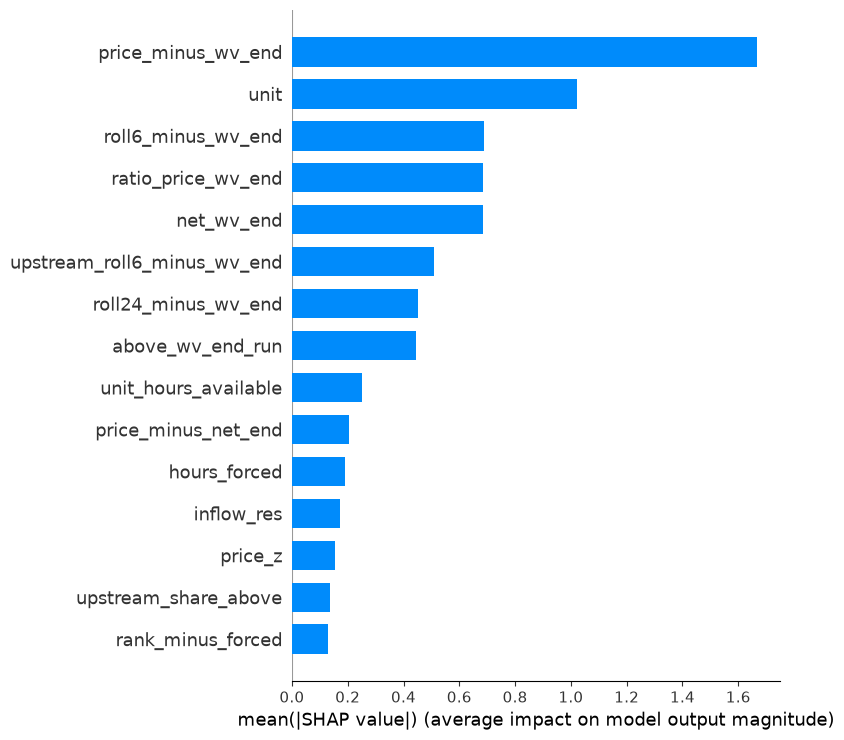

In [13]:
%%script false --no-raise-error
# ^ SKIPPED for now (LightGBM, slow). Delete the line above to run this cell again.
shap.summary_plot(shap_values, sample_num, plot_type="bar", max_display=15)

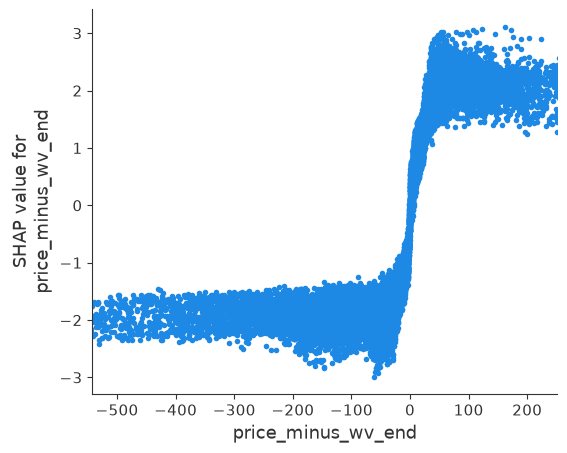

In [14]:
%%script false --no-raise-error
# ^ SKIPPED for now (LightGBM, slow). Delete the line above to run this cell again.
shap.dependence_plot("price_minus_wv_end", shap_values, sample_num,
                     interaction_index=None,
                     xmin="percentile(1)", xmax="percentile(99)")

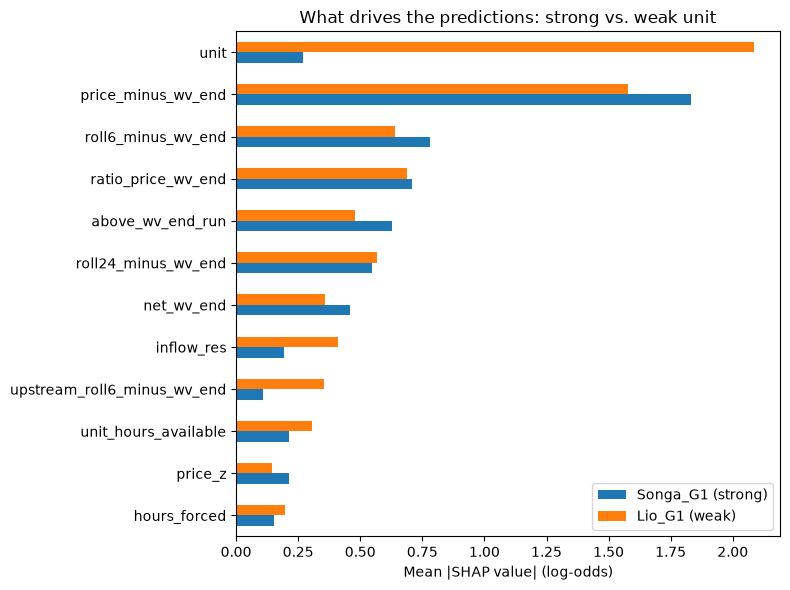

In [15]:
%%script false --no-raise-error
# ^ SKIPPED for now (LightGBM, slow). Delete the line above to run this cell again.
def mean_abs_shap(unit):
    mask = (sample["unit"] == unit).to_numpy()
    return pd.Series(np.abs(shap_values[mask]).mean(axis=0), index=features)

compare = pd.DataFrame({
    "Songa_G1 (strong)": mean_abs_shap("Songa_G1"),
    "Lio_G1 (weak)": mean_abs_shap("Lio_G1"),
})
top = compare.max(axis=1).sort_values(ascending=False).index[:12]

ax = compare.loc[top][::-1].plot.barh(figsize=(8, 6))
ax.set_xlabel("Mean |SHAP value| (log-odds)")
ax.set_title("What drives the predictions: strong vs. weak unit")
plt.tight_layout()

In [16]:
%%script false --no-raise-error
# ^ SKIPPED for now (LightGBM, slow). Delete the line above to run this cell again.
# Final model: v5 and v6 trained on all of 2015–2022, predictions averaged
version = "v7_avg"   # change for each new submission
w5 = 0.5             # weight on v5, chosen from the validation table above

# Predict the test cases (2023–2024)
X_test = build_features(test_cases["starttime"])

def fit_predict(feats):
    m = lgb.LGBMClassifier(**params).fit(X[feats], y)
    return m.predict_proba(X_test[feats])[:, 1]

p_test = w5 * fit_predict(v6_features + absolute_levels) + (1 - w5) * fit_predict(v6_features)
# p_test = smooth(p_test, 5)   # only if smoothing helped on validation (needs the smoothing cell to have run)

# Back to Kaggle format: one row per case, columns in the same order as the labels
P_test = p_test.reshape(len(units), len(test_cases), 168).transpose(1, 0, 2)   # (cases, units, hours)
submission = pd.DataFrame(P_test.reshape(len(test_cases), -1), columns=label_cols)
submission.insert(0, "Run No", test_cases["Run No"].to_numpy())

# Check against the sample file before saving
sample_sub = pd.read_csv("sample_submission.csv")
assert list(submission.columns) == list(sample_sub.columns)
assert (submission["Run No"].to_numpy() == sample_sub["Run No"].to_numpy()).all()

submission.to_csv(f"submission_lgbm_{version}.csv", index=False)
submission.shape   # (725, 2353)

(725, 2353)